# Topic Modeling with LDA and LSA using Spacy, Sklearn and Gensim

Topic modeling is a technique used to extract the underlying topics or themes from a large corpus of text. It has applications in a wide range of fields, from information retrieval to social sciences. In this tutorial, we will explore two popular methods for topic modeling: Latent Dirichlet Allocation (LDA) and Latent Semantic Analysis (LSA).

We will use two different datasets to showcase the capabilities of these models: news articles and customer support.

To implement LDA and LSA models, we will use two popular Python libraries: scikit-learn (sklearn) and gensim. Sklearn is a general-purpose machine learning library, while gensim is specifically designed for text processing.

By the end of this tutorial, you will have a better understanding of what you can do with LDA and LSA, and how to implement them using sklearn and gensim. You will also be able to apply these techniques to your own text data to extract meaningful topics and themes. Let's get started!

## News dataset

Start by downloading the data by executing the command below:

In [1]:
!gdown 1M1Ok5eh4Y28AXi_zS5c3Z57FbVbQazn-

Downloading...
From (original): https://drive.google.com/uc?id=1M1Ok5eh4Y28AXi_zS5c3Z57FbVbQazn-
From (redirected): https://drive.google.com/uc?id=1M1Ok5eh4Y28AXi_zS5c3Z57FbVbQazn-&confirm=t&uuid=fbfaba40-9178-4155-951a-82e47475358f
To: /home/magikdidi/Downloads/FrenchNews.csv
100%|████████████████████████████████████████| 120M/120M [00:24<00:00, 4.95MB/s]


### Data preparation and EDA

As usual, lets start with data preparation. This time, we will try using spacy (https://spacy.io/models/fr) and we will perform the following operations:

* Only keep the first 10k of texts
* Remove all rows where the `Contenu` is not a string.
* Convert the texts to lowercase
* Tokenize them and convert the tokens to lemmas (ignore stopwords, punctuation, and numbers using is_stop, is_punct)
* Join the tokens to reconstruct the clean texts.

Lets use the model `fr_core_news_md` which has a tokenizer and lemmatizer and write a function preprocess_text to perform the operations above and apply it to the column `Contenu` of our dataframe to create a new column called `clean_text`.

In [2]:
!python -m spacy download fr_core_news_md
!python -m spacy download en_core_web_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 MB 7.6 MB/s  0:00:06 eta 0:00:010:00:01

[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('fr_core_news_md')
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 2.8 MB/s  0:00:11 eta 0:00:010:00:01

[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')


In [3]:
import pandas as pd
import spacy

# Load the csv file into a pandas dataframe
df = pd.read_csv('FrenchNews.csv').iloc[:10000]
df = df[df['Contenu'].apply(lambda x:isinstance(x,str))]

# Load the spacy model for French
nlp = spacy.load('fr_core_news_md')

# Define a function to preprocess the text
def preprocess_text(text):
    # Convert the text to lowercase
    text=text.lower()
    # Tokenize the text using spacy
    doc = nlp(text)
    # Remove stopwords, punctuation, and get lemma using tokens attributes like 'is_stop'
    lemmas = [
        token.lemma_
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and token.lemma_.strip()!= ""
    ]
    # Join the lemmatized tokens back into a string
    clean_text = ' '.join(lemmas)
    return clean_text

# Apply the preprocess_text function to the "Contenu" column to create a new column "clean_text"
df['clean_text'] = df['Contenu'].apply(preprocess_text)

In [4]:
df

,Numero news,Numero page,Numero,Date,Heure,Titre,Contenu,Agency,URL,textURL,...,seconds to 2010,days to 2010,dateDT,Title eng,Content eng,textURL eng,Sentiment Vader Title,Sentiment Vader Text,Sentiment Vader TextURL,clean_text
0,1,2127,18,19.10.2017,08:57,Marseille : une baleine de 15 mètres piégée da...,C'est une drôle de découverte qu'ont faite ce ...,Le Point,https://www.boursorama.com/actualite-economiqu...,C'est une drôle de découverte qu'ont faite ce ...,...,246099420.0,2848.372917,2017-10-19 08:57:00,Marseille: a 15 metre whale trapped in the Old...,This is a strange discovery that the Marseilla...,It's a strange discovery that the Marseillais ...,-0.5267,0.3612,0.8689,drôle découverte faire midi marseillais cétacé...
1,2,2127,17,19.10.2017,10:35,"Le Burkinabé qui a stoppé le désert, l'intox d...",L'émission de cette semaine nous emmène au Bur...,France 24,https://www.boursorama.com/videos/actualites/l...,L'émission de cette semaine nous emmène au Bur...,...,246105300.0,2848.440972,2017-10-19 10:35:00,"The Burkinabe who stopped the desert, the into...",This week's show takes us to Burkina Faso to m...,This week's show takes us to Burkina Faso to m...,-0.2263,-0.6486,-0.1531,émission semaine emmener burkina faso rencontr...
2,3,2127,16,19.10.2017,10:59,"En Grande-Bretagne, les ventes au détail subis...",LONDRES (Reuters) - Les ventes au détail en Gr...,Reuters,https://www.boursorama.com/actualite-economiqu...,LONDRES (Reuters) - Les ventes au détail en Gr...,...,246106740.0,2848.457639,2017-10-19 10:59:00,"In Great Britain, retail sales stopped in Sept...",LONDON (Reuters) - Retail sales in Great Brita...,LONDON (Reuters) - Retail sales in Great Brita...,0.4939,0.3182,-0.4019,londre reuters vente détail grande-bretagne su...
3,4,2127,15,19.10.2017,11:40,Antiterrorisme : Bruxelles fait avec les moyen...,La sécurité ne fait pas partie des prérogative...,Le Point,https://www.boursorama.com/actualite-economiqu...,La sécurité ne fait pas partie des prérogative...,...,246109200.0,2848.486111,2017-10-19 11:40:00,Anti-terrorism: Brussels made with the means o...,Security is not part of the European Union's p...,Security is not part of the European Union's p...,0.0000,0.3400,-0.9748,sécurité partie prérogative union européen éta...
4,5,2127,14,19.10.2017,11:58,"Dmitri Rybolovlev, président de l'AS Monaco, i...","NICE (Reuters) - Le président de l'AS Monaco, ...",Reuters,https://www.boursorama.com/actualite-economiqu...,"NICE (Reuters) - Le président de l'AS Monaco, ...",...,246110280.0,2848.498611,2017-10-19 11:58:00,"Dmitri Rybolovlev, President of AS Monaco, cha...","NICE (Reuters) - The president of AS Monaco, D...","NICE (Reuters) - The president of AS Monaco, D...",-0.2023,-0.3954,0.9386,nice reuters président monaco dmitri rybolovle...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,1615,1,07.05.2019,14:43,Gilets jaunes: Procès en vue pour une militant...,"TOULOUSE (Reuters) - Odile Maurin, figure hist...",Reuters,https://www.boursorama.com/actualite-economiqu...,"TOULOUSE (Reuters) - Odile Maurin, figure hist...",...,294936180.0,3413.613194,2019-05-07 14:43:00,Yellow jackets: Trial in sight for a wheelchai...,"TOULOUSE (Reuters) - Odile Maurin, the histori...","TOULOUSE (Reuters) - Odile Maurin, a historica...",0.0000,-0.7845,-0.8225,toulouse reuters odile maurin figure historiqu...
9996,9997,1614,20,07.05.2019,14:50,Municipale annulée à Istanbul : c'est une sit...,"Marc Pierini, ancien ambassadeur de l'UE en Tu...",France 24,https://www.boursorama.com/videos/actualites/m...,NaN,...,294936600.0,3413.618056,2019-05-07 14:50:00,Municipal canceled in Istanbul: it is a situat...,"Marc Pierini, former EU Ambassador to Turkey (...",Empty.,0.1779,0.0000,0.0000,marc pierini ancien ambassadeur ue turquie 200...
9997,9998,1614,19,07.05.2019,14:55,Gilets jaunes: Philippe défend la politique de...,PARIS (Reuters) - A 19 jours des élections eur...,Reuters,https://www.boursorama.com/act

Now that we have a clean text, lets analyze their length and then build the term-document matrix:

* Compute the length of each document in the "clean_text" column and store it in a new column "doc_len"
* Compute the word count of each document in the "clean_text" column and store it in a new column "word_count"
* Display the descriptive statistics of the "doc_len" and "word_count" columns. Plot some their distribution in histogram using the code from last practical exercise.
* Generate the term-document matrix using CountVectorizer.
* Plot the top 20 most frequent words using the code from last practical exercise.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer


# Compute the length of each document in the "clean_text" column
df['doc_len'] = df['clean_text'].str.len()

# Compute the word count of each document in the "clean_text" column
df['word_count'] = df['clean_text'].str.split().str.len()

# Display the descriptive statistics of the "doc_len" and "word_count" columns
print(df[['doc_len', 'word_count']].head(10))

# Generate the term-document matrix using CountVectorizer
vectorizer = CountVectorizer()
term_document_matrix = vectorizer.fit_transform(df['clean_text'])

   doc_len  word_count
0      152          20
1      156          18
2      312          38
3       88          11
4      316          43
5      281          34
6      105          13
7      256          31
8      342          40
9       75          11


In [6]:
# use code from last time to show most frequent terms
vectorizer.vocabulary_

{'drôle': 6343,
 'découverte': 6536,
 'faire': 7812,
 'midi': 12878,
 'marseillais': 12520,
 'cétacé': 5618,
 '15': 113,
 'mètre': 13411,
 'entrer': 7340,
 'vieux': 20370,
 'port': 15349,
 'savoir': 17750,
 'police': 15262,
 'national': 13607,
 'appeler': 1750,
 'rescousse': 16730,
 'marin': 12475,
 'pompier': 15306,
 'marseille': 12521,
 'mercredi': 12788,
 'émission': 21203,
 'semaine': 17913,
 'emmener': 7136,
 'burkina': 3430,
 'faso': 7879,
 'rencontre': 16625,
 'homme': 9680,
 'septuagénaire': 17952,
 'stopper': 18639,
 'désert': 6832,
 'découvrir': 6537,
 'théorie': 19357,
 'complotiste': 4795,
 'chemtrail': 4199,
 'baser': 2592,
 'manipulation': 12376,
 'image': 10023,
 'répandre': 17370,
 'londre': 11950,
 'reuters': 16824,
 'vente': 20239,
 'détail': 6873,
 'grande': 9073,
 'bretagne': 3281,
 'subir': 18703,
 'septembre': 17949,
 'coup': 5307,
 'arrêt': 1943,
 'brutal': 3369,
 'ampleur': 1490,
 'inattendu': 10143,
 'point': 15231,
 'tomber': 19462,
 'croissance': 5453,
 'trim

# LSA

LSA is implemented in scikit-learn `sklearn.decomposition.TruncatedSVD`.

Here the objective is to:
* Perform LSA on the term-document matrix using sklearn with 10 components
* Display the obtained topics with their main words
* Display five documents from each topic.

In [7]:
from sklearn.decomposition import TruncatedSVD
# Perform LSA on the term-document matrix using Sklearn
n_components = 10
lsa = TruncatedSVD(n_components=n_components)
lsa_tdm = lsa.fit_transform(term_document_matrix)

# Display the different topics with their main words
feature_names = vectorizer.get_feature_names_out()
for i, component in enumerate(lsa.components_):
    print(f"Topic {i}:")
    print(component)

Topic 0:
[2.05475090e-04 1.32588109e-02 8.96455006e-05 ... 2.44539520e-05
 1.20717136e-03 9.06138693e-05]
Topic 1:
[-2.37031077e-04 -6.96743914e-03 -1.51966807e-04 ... -9.10167893e-05
  3.04504710e-04 -7.77640693e-05]
Topic 2:
[-1.19063195e-04  1.97006505e-02  3.36349928e-04 ...  6.37680034e-05
  7.18358448e-04  1.51099508e-04]
Topic 3:
[-5.45926743e-04 -7.42894183e-03 -4.30832157e-05 ... -1.03059114e-04
 -6.92716165e-04  5.72635608e-05]
Topic 4:
[-4.15814004e-04 -1.19841860e-02  1.97209804e-04 ... -1.03738215e-04
  3.57720072e-04  7.71563760e-05]
Topic 5:
[-3.24496823e-04  9.15552909e-03 -1.79910740e-04 ... -3.72654337e-06
  1.95817225e-03  3.18442027e-05]
Topic 6:
[-8.21839898e-04 -2.25958502e-03 -6.77633456e-06 ... -7.09830270e-06
 -4.54198836e-04  8.69152569e-05]
Topic 7:
[ 3.39232797e-04  1.15084263e-02 -2.74058383e-04 ...  3.85107542e-05
  1.77455354e-03 -1.84245519e-04]
Topic 8:
[ 2.02847625e-04  4.76179977e-04 -4.22718306e-05 ...  5.23507496e-05
  7.77635822e-04 -1.38987681e-04

In [8]:
# get topic with highest value for each document
document_topics = lsa_tdm.argmax(axis=1)

In [25]:
for i in range(n_components):
    print(f"\n=== Topic {i} ===")
    topic_docs = df[document_topics == i]['clean_text'].head(5)
    for j, doc in enumerate(topic_docs):
        print(f"\nDoc {j+1}: {doc[:300]}...")



=== Topic 0 ===

Doc 1: drôle découverte faire midi marseillais cétacé 15 mètre entrer vieux-port savoir police national appeler rescousse marin pompier marseille mercredi midi...

Doc 2: émission semaine emmener burkina faso rencontre homme septuagénaire stopper désert découvrir théorie complotiste chemtrail baser manipulation image répandre...

Doc 3: londre reuters vente détail grande-bretagne subir septembre coup arrêt brutal ampleur inattendu point faire tomber croissance trimestriel rythme faible 2013 nettement progresser août contracter 0,8 mois dernier annoncer jeudi office national statistique résultat inférieur prévision économiste interr...

Doc 4: pari reuters agent police sécurité quotidien équiper tablette numérique mettre amende immédiat personne rendre responsable harcèlement rue annoncer jeudi gérard collomb grâce tablette policier pouvoir prendre coordonnée regarder être ficher poursuivre ministre intérieur franceinfo...

Doc 5: pari reuters député européen commissio

Let us also vizualize the magnitude of each topic in a bar chart:
* Convert values in document_topics with top 3 words of topic.
*  Convert to dataframe and use seaborn countplot to display the histogram

In [26]:
top_words_per_topic = []
for topic in lsa.components_:
    #print(topic)
    top_indices = topic.argsort()[-3:][::-1]
    #print(top_indices)
    top_words = [feature_names[i] for i in top_indices]
    #print(top_words)
    top_words_per_topic.append(" ".join(top_words))

for i, words in enumerate(top_words_per_topic):
    print(f"Topic {i}: {words}")

document_topic_labels = []
for topic_idx in document_topics:
    label = top_words_per_topic[topic_idx]
    document_topic_labels.append(label)


Topic 0: reuters pari france
Topic 1: pari gilet jaune
Topic 2: être an milliard
Topic 3: européen reuters pari
Topic 4: être européen président
Topic 5: france an français
Topic 6: français emmanuel macron
Topic 7: an pari européen
Topic 8: français pari européen
Topic 9: ministre gouvernement an


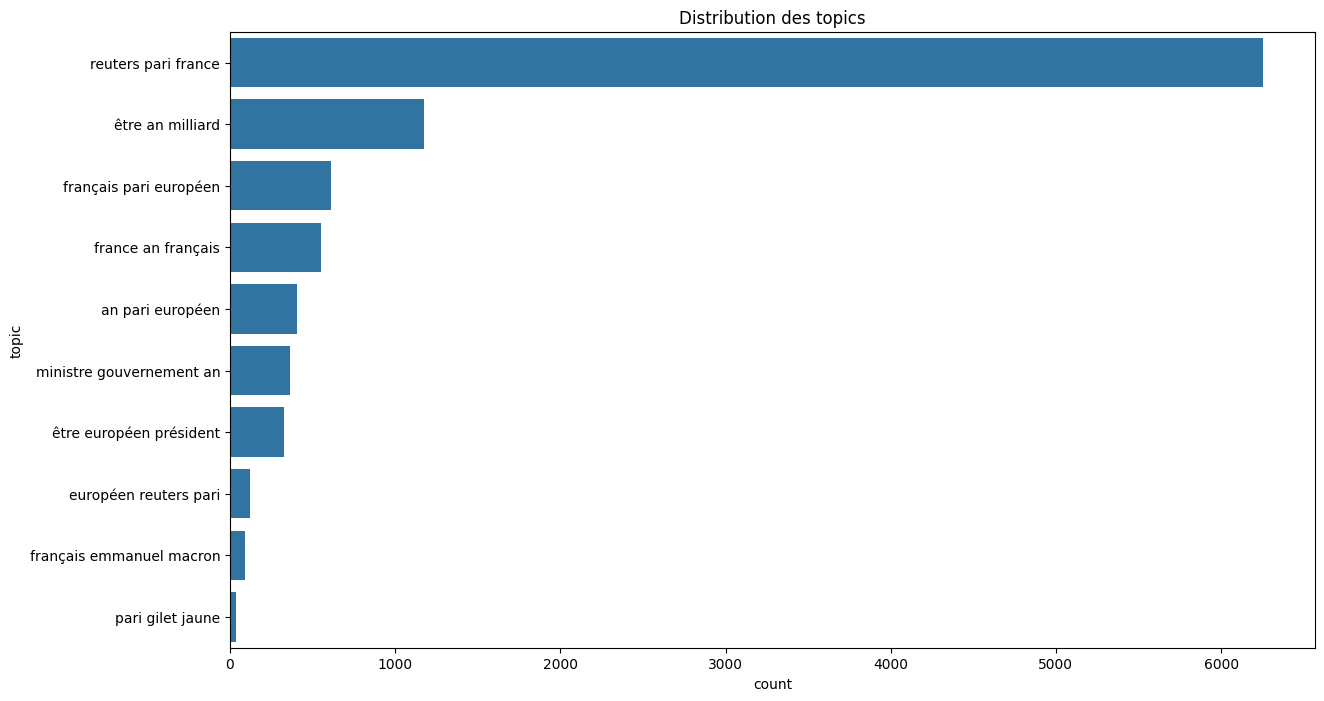

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

df_topics = pd.DataFrame({'topic': document_topic_labels})

plt.figure(figsize=(14, 8))
sns.countplot(data=df_topics, y='topic', order=df_topics['topic'].value_counts().index)
plt.title("Distribution des topics")
plt.show()


We can go further with vizualization by plotting the whole corpus of documents and their topic. For that we can:
* Apply a dimensionality reduction (TSNE from sklearn.manifold) on their topic representation
* We can then display them in a 2D grid (plt.scatter) one by one (they will each have a different color according to their main topic).
* We can use a few words caracterizing the topic a legend.

[t-SNE] Computing 121 nearest neighbors...
[t-SNE] Indexed 9941 samples in 0.011s...
[t-SNE] Computed neighbors for 9941 samples in 0.918s...
[t-SNE] Computed conditional probabilities for sample 1000 / 9941
[t-SNE] Computed conditional probabilities for sample 2000 / 9941
[t-SNE] Computed conditional probabilities for sample 3000 / 9941
[t-SNE] Computed conditional probabilities for sample 4000 / 9941
[t-SNE] Computed conditional probabilities for sample 5000 / 9941
[t-SNE] Computed conditional probabilities for sample 6000 / 9941
[t-SNE] Computed conditional probabilities for sample 7000 / 9941
[t-SNE] Computed conditional probabilities for sample 8000 / 9941
[t-SNE] Computed conditional probabilities for sample 9000 / 9941
[t-SNE] Computed conditional probabilities for sample 9941 / 9941
[t-SNE] Mean sigma: 0.000000
[t-SNE] KL divergence after 250 iterations with early exaggeration: 75.532104
[t-SNE] KL divergence after 1000 iterations: 1.170905


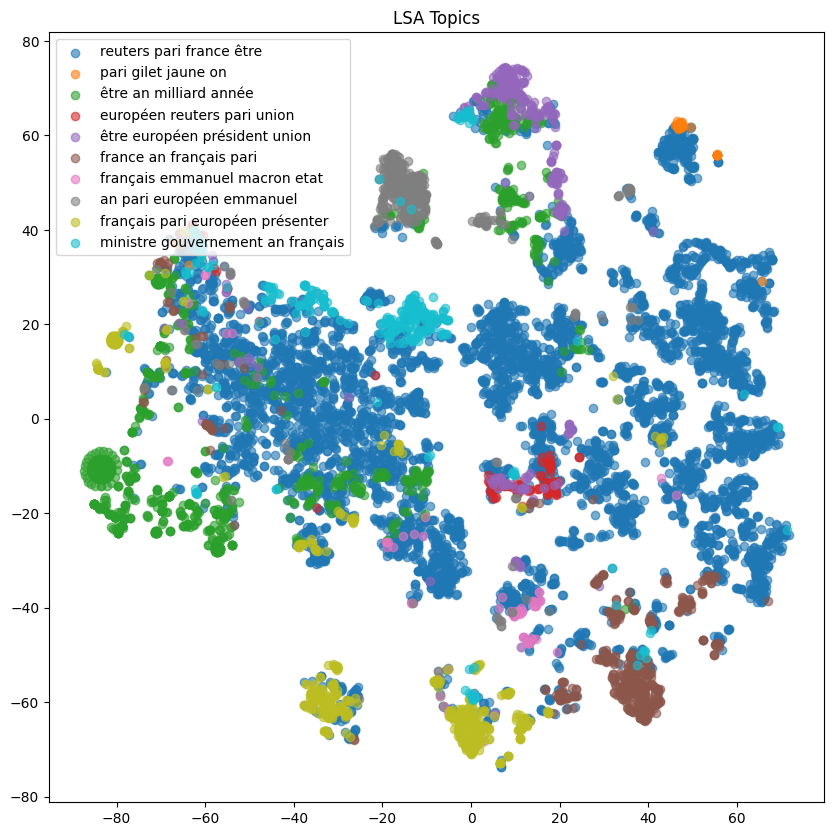

In [30]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# TSNE sur la représentation LSA (documents × topics)
tsne = TSNE(n_components=2, verbose=1, perplexity=40)
tsne_lda = tsne.fit_transform(lsa_tdm)

plt.figure(figsize=(10, 10))

# Description de chaque topic avec ses 4 mots principaux
num_top_words_desc = 4
topics_desc = [
    " ".join([feature_names[i] for i in topic.argsort()[:-num_top_words_desc - 1:-1]])
    for topic in lsa.components_
]

# Un scatter par topic pour avoir une légende correcte
for i, t in enumerate(topics_desc):
    mask = document_topics == i
    plt.scatter(tsne_lda[mask, 0], tsne_lda[mask, 1], label=t, alpha=0.6)

plt.legend()
plt.title("LSA Topics")
plt.show()


This will provide a good comparison point with others methods.

### LDA - Latent Dirichlet Allocation

Let us now experiment with LDA. We'll start with the sklearn implementation and do the following:

* Split the term-document matrix into train and validation sets using train_test_split from sklearn.model_selection.
* Perform LDA on the training term-document matrix using LatentDirichletAllocation from sklearn.decomposition with 5 topics.
* Display the different topics with their main words.
* Evaluate the performance on validation by calculating the perplexity score using score method from LDA and np.exp from numpy.
* Reduce dimensionality of document topics using TSNE from sklearn.manifold and do some interesting visualization using plotly.

Put step 2 to 4 in a function so that you can then test several values for the number of topics.

In [ ]:
# Split the term-document matrix into train and validation sets
from sklearn.model_selection import train_test_split

X_train, X_val = train_test_split()

# Perform LDA on the term-document matrix train set using Sklearn with 5 topics
from sklearn.decomposition import LatentDirichletAllocation

lda = LatentDirichletAllocation
...

# Display the different topics with their main words
import numpy as np

def display_topics(model, feature_names, num_top_words):
    ...

num_top_words = 10
display_topics(lda, feature_names, num_top_words)

# Evaluate the performance on validation
from sklearn.metrics import log_loss

log_likelihood = ...
perplexity = np.exp(-log_likelihood / X_val.shape[0])
print('Perplexity: ', perplexity)

# Reduce dimensionality of document topics using TSNE
from sklearn.manifold import TSNE


# fit a TSNE model on LDA document topic representation

# Do some interesting visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

# plot the document and topics

In [ ]:
# print top 5 examples for each topic

for i in range(...):
    ...

### Customer Support Dataset

Let us now consider another dataset and try experimenting with another library (gensim).

In [ ]:
!gdown --id 1mT1SbSgBbElkHUybHugW32w8_hIN_eH0

Start by rewriting your preprocessing code but with gensim instead. And save the preprocessed text in a new column called `clean_text_tokens`.

For that let us use `preprocess_string` from `gensim.parsing.preprocessing` with several processing functions (to lower case, removing stop words, removing punctuation, stemming)

https://radimrehurek.com/gensim/parsing/preprocessing.html

In [ ]:
from gensim.parsing.preprocessing import preprocess_string, ...

# Load the dataset
df = pd.read_csv("/content/customer_requests.csv")

# preprocess given text
def preprocess(text):

    # clean text based on given filters (here add other functions for stemming, removing punct, etc..)
    CUSTOM_FILTERS = [lambda x: x.lower(), ...]
    text = preprocess_string(text, CUSTOM_FILTERS)

    return text

# Apply the preprocess function to the text column
df["clean_text_tokens"] = df["utterance"]...

Next, let's apply LDA like we just did before but this time we want to using gensim:
* Generate the term-document matrix using `Dictionary` from `gensim.corpora` and its method `doc2bow`.
* Split the term-document matrix into train and validation sets using train_test_split() from sklearn.
* Train an LDA model on the term-document matrix train set using gensim. Set the number of topics to 15.
* Print the main words for each topic using the print_topics() method of the LDA model.
* Evaluate the performance of the LDA model on the validation set using the perplexity metric.
* Reduce the dimensionality of the document topics using TSNE from sklearn.manifold.
* Visualize the topics using matplotlib.pyplot.scatter().

In [ ]:
import gensim
from gensim import corpora
from gensim.models.ldamodel import LdaModel
from sklearn.metrics import log_loss

# Split the df into train and validation sets
df_train, df_val = ...

# Perform LDA on the term-document matrix train set using gensim with 15 topics
num_topics = 15
id2word = # create a corpora.Dictionary on the tokens
corpus = [] # use the Dictionary method doc2bow to vectorize the corpus
lda_model = LdaModel(corpus=corpus,
                     id2word=id2word,
                     num_topics=num_topics,
                     random_state=42,
                     chunksize=100,
                     passes=10)

# Display the different topics with their main words
for idx, topic in lda_model.print_topics(-1):
    print(f'Topic: {idx} \nWords: {topic}\n')

# Evaluate the performance on validation
val_corpus = [] # vectorize the validation corpus
log_likelihood = # use the model log_perplexity function
perplexity = # apply exp(-log_perplexity)
print(f'Perplexity: {perplexity}')

# Reduce dimensionality of document topics using TSNE
all_topics_numpy = gensim.matutils.corpus2csc(lda_model.get_document_topics(corpus)).T.toarray()

#apply TSNE all_topics_numpy as usual and do the same visualization as previously


With LDA, there is an interesting vizualization library to get insights about the topics called pyLDAviz. Let us try it out:

In [ ]:
!pip install pyldavis

In [ ]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

# Visualize the topics
vis = gensimvis.prepare(lda_model, corpus, id2word, sort_topics=False)
pyLDAvis.display(vis)

### Using clustering

Try to come up with another way to generate topics but with a clustering technique like kmeans. Implement it and test it (try using Tfidf here).

In [ ]:
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = ...
term_document_matrix = ...

num_clusters = 15
...